# Notebook 2: Entrenamiento y comparación de modelos
**Trabajo Práctico: Sistema de Reconocimiento Facial**
Visión por Computadora. Tecnicatura Universitaria en Inteligencia Artificial (FCEIA, UNR).

## Alumno
Marco Ippolito

## Objetivo
Comparar dos enfoques para generar embeddings faciales, sobre el mismo conjunto de test y con las mismas métricas:
- **Modelo A, CNN propia:** red convolucional diseñada y entrenada desde cero con el dataset curado en la notebook 1.
- **Modelo B, ArcFace (InsightFace `buffalo_l`):** modelo preentrenado de estado del arte, usado como extractor de embeddings.

Al final se elige el modelo para la app y se calibra el umbral de similitud.

## 0. Preparación del entorno
Se monta Drive, se instalan las librerías, se clona el repositorio (para usar el mismo `face_pipeline.py` que la app) y se definen las rutas a los modelos y a los datos procesados en la notebook 1.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE = '/content/drive/MyDrive/TP_FaceRec'
MODELOS = f'{BASE}/models'        # modelos InsightFace + modelos entrenados acá
PROCESADO = f'{BASE}/procesado'   # salidas de la notebook 1

!pip install -q insightface==0.7.3 onnxruntime-gpu albumentations onnx2torch

REPO_URL = 'https://github.com/MarcoIppolito96/Aplicacion-Reconocimiento-Facial'
REPO = f'{BASE}/repo'
if not os.path.exists(REPO):
    !git clone -b feature/tp-reconocimiento-facial {REPO_URL} {REPO}
else:
    !git -C {REPO} pull
sys.path.insert(0, f'{REPO}/src')  # mismo face_pipeline.py que usa la app

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from lib import face_pipeline as fp

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already up to date.


## 1. Datos
Se cargan las caras alineadas (112×112), los embeddings ArcFace y la partición generada en la notebook 1. La CNN se entrena como clasificador sobre las **85 identidades closed-set**: cada identidad es una clase. Las 20 identidades open-set no tienen clase porque el modelo nunca las ve.

In [2]:
caras_alineadas = np.load(f'{PROCESADO}/caras_alineadas.npy')       # (N, 112, 112, 3) BGR uint8
emb_arcface_todas = np.load(f'{PROCESADO}/embeddings_arcface.npy')  # (N, 512) ArcFace, normalizados L2
splits = pd.read_csv(f'{PROCESADO}/splits.csv')

ids_train = np.sort(splits.loc[splits['split'] == 'train', 'identidad'].unique())
clase_de = {ident: i for i, ident in enumerate(ids_train)}  # identidad -> número de clase (solo closed-set)
por_split = {s: splits[splits['split'] == s].reset_index(drop=True) for s in ['train', 'val', 'test_closed', 'test_open']}
print(f'Caras alineadas: {caras_alineadas.shape} | clases de entrenamiento: {len(ids_train)}')
print(splits['split'].value_counts().to_string())

Caras alineadas: (17528, 112, 112, 3) | clases de entrenamiento: 85
split
train          11094
test_open       3020
val             1387
test_closed     1387


## 2. Modelo A: CNN propia

### 2.1 Dataset y augmentation
Cada cara pasa por el **mismo preprocesamiento que usa la app** (`fp.preprocesar`): BGR → RGB, píxeles escalados a [-1, 1] y formato canales-alto-ancho. La augmentation definida en la notebook 1 se aplica **solo al conjunto de entrenamiento**.

In [3]:
import time
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A

torch.manual_seed(42); np.random.seed(42)
dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'

# Mismo pipeline de augmentation definido en la notebook 1 (sección 6)
aumentacion = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05), border_mode=cv2.BORDER_REFLECT_101, p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.6),
    A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=20, val_shift_limit=0, p=0.3),
    A.ToGray(p=0.1),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=(3, 5))], p=0.2),
    A.GaussNoise(std_range=(0.02, 0.06), p=0.15),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.15, 0.3), hole_width_range=(0.15, 0.3), fill=0, p=0.3),
    A.ImageCompression(quality_range=(40, 90), p=0.3),
])

class CarasDataset(Dataset):
    def __init__(self, tabla, aumentar=False):
        self.idx = tabla['idx_cara'].astype(int).to_numpy()
        self.y = tabla['identidad'].map(clase_de).fillna(-1).astype(int).to_numpy()  # -1 = identidad sin clase (open-set)
        self.aumentar = aumentar
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        cara = caras_alineadas[self.idx[i]]
        if self.aumentar:
            cara = aumentacion(image=cara)['image']  # augmentation SOLO en train
        x = torch.from_numpy(fp.preprocesar(cara)[0])  # mismo preprocesamiento que la app: RGB, [-1, 1], CHW
        return x, self.y[i]

cargador_train = DataLoader(CarasDataset(por_split['train'], aumentar=True), batch_size=128, shuffle=True, num_workers=2, drop_last=True)
cargador_val = DataLoader(CarasDataset(por_split['val']), batch_size=256, num_workers=2)
x, y = next(iter(cargador_train))
print(f'Lote de entrenamiento: {tuple(x.shape)} | rango [{x.min():.2f}, {x.max():.2f}] | dispositivo: {dispositivo}')

Lote de entrenamiento: (128, 3, 112, 112) | rango [-1.00, 1.00] | dispositivo: cuda


**Resultado:** cada lote tiene 128 caras de 3 × 112 × 112, con valores entre -1 y 1 (escala que espera el modelo y que usa la app) y se procesa en la GPU (`cuda`).

### 2.2 Arquitectura
Enfoque **clasificación + embedding**: la red se entrena para clasificar las 85 identidades, pero lo que se usa en la app es la **capa previa al clasificador** (128 dimensiones, normalizada L2) como embedding. El clasificador solo existe para entrenar.

| Parte | Capas | Salida |
|---|---|---|
| Entrada | Cara alineada RGB | 3 × 112 × 112 |
| Bloque 1 | 2 × (Conv 3×3 → BatchNorm → ReLU) → MaxPool | 32 × 56 × 56 |
| Bloque 2 | ídem | 64 × 28 × 28 |
| Bloque 3 | ídem | 128 × 14 × 14 |
| Bloque 4 | ídem | 256 × 7 × 7 |
| Global Average Pooling | Promedio de cada mapa | 256 |
| Dropout 30% + Linear + BatchNorm | **Embedding** | **128** |
| Linear (solo entrenamiento) | Clasificador | 85 |

**Justificación:**
- **4 bloques convolucionales** con filtros que se duplican (32 → 256): la imagen se reduce de 112 a 7 píxeles mientras la descripción se vuelve más rica (de bordes a rasgos faciales). Es una red chica, acorde a unas 11.000 imágenes de entrenamiento.
- **BatchNorm:** normaliza las activaciones entre capas, lo que estabiliza y acelera el entrenamiento.
- **Global Average Pooling** en lugar de aplanar: convierte 256×7×7 en 256 números con **cero parámetros**. Aplanar generaría unos 12.500 valores y millones de pesos en la capa siguiente, con más riesgo de overfitting.
- **Dropout 30%:** apaga neuronas al azar al entrenar, para que la red no dependa de un solo rasgo.
- **Embedding sin ReLU:** puede tener valores negativos, lo que aprovecha mejor el espacio para la similitud coseno.

In [4]:
def bloque(c_in, c_out):
    # Dos convoluciones 3x3 + BatchNorm + ReLU y un MaxPool que reduce el tamaño a la mitad
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class CNNFacial(nn.Module):
    def __init__(self, n_clases, dim_embedding=128):
        super().__init__()
        self.backbone = nn.Sequential(bloque(3, 32), bloque(32, 64), bloque(64, 128), bloque(128, 256))  # 112 -> 7
        self.pool = nn.AdaptiveAvgPool2d(1)                       # Global Average Pooling: 256x7x7 -> 256
        self.dropout = nn.Dropout(0.3)
        self.embedding = nn.Sequential(nn.Linear(256, dim_embedding), nn.BatchNorm1d(dim_embedding))  # vector de identidad
        self.clasificador = nn.Linear(dim_embedding, n_clases)    # solo para entrenar; la app no lo usa

    def extraer_embedding(self, x):
        return self.embedding(self.dropout(self.pool(self.backbone(x)).flatten(1)))

    def forward(self, x):
        return self.clasificador(self.extraer_embedding(x))

modelo_a = CNNFacial(n_clases=len(ids_train)).to(dispositivo)
n_param = sum(p.numel() for p in modelo_a.parameters())
n_param_emb = n_param - sum(p.numel() for p in modelo_a.clasificador.parameters())
print(modelo_a)
print(f'\nParámetros totales: {n_param:,} | sin el clasificador (lo que usa la app): {n_param_emb:,}')

CNNFacial(
  (backbone): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inpl

**Resultado:** la CNN tiene **1.217.333 parámetros** en total, de los cuales **1.206.368** forman el extractor de embeddings que usa la app. El clasificador (128 → 85) suma solo unos 11.000 parámetros y se descarta después del entrenamiento. Como referencia, ArcFace (ResNet-50) tiene unos 43 millones de parámetros, unas **35 veces más**.

### 2.3 Entrenamiento
| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Pérdida | Cross-entropy con *label smoothing* 0,1 y pesos por clase | Estándar para clasificación multiclase. El *label smoothing* evita que la red esté "100% segura", lo que da embeddings más generales. Los pesos compensan el desbalance (2,8x) |
| Optimizador | AdamW, lr = 0,001, weight decay = 0,0005 | Adam ajusta el paso de cada peso; el *weight decay* penaliza pesos grandes (regularización) |
| Scheduler | Cosine annealing | Baja el learning rate gradualmente: pasos grandes al principio y finos al final |
| Batch size | 128 | Entra cómodo en la GPU T4 |
| Épocas | Hasta 30, *early stopping* con paciencia 5 | Corta si la accuracy de validación no mejora en 5 épocas y se queda con el mejor checkpoint |

El modelo y el historial se guardan en Drive. Si ya existen, se cargan en lugar de reentrenar.

In [5]:
EPOCAS, PACIENCIA = 30, 5
ARCH_MODELO_A = f'{MODELOS}/cnn_propia_mejor.pth'
ARCH_HISTORIAL = f'{MODELOS}/cnn_propia_historial.csv'

# Pesos por clase: las identidades con menos fotos pesan más en la pérdida (compensa el desbalance)
conteo_clases = np.bincount(cargador_train.dataset.y, minlength=len(ids_train))
pesos = torch.tensor(conteo_clases.sum() / (len(conteo_clases) * conteo_clases), dtype=torch.float32).to(dispositivo)
criterio = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.1)
optimizador = torch.optim.AdamW(modelo_a.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=EPOCAS)

def una_epoca(cargador, entrenar):
    modelo_a.train(entrenar)
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            logits = modelo_a(x)
            perdida = criterio(logits, y)
            if entrenar:
                optimizador.zero_grad(); perdida.backward(); optimizador.step()
            perdida_total += perdida.item() * len(y); aciertos += (logits.argmax(1) == y).sum().item(); n += len(y)
    return perdida_total / n, aciertos / n

if os.path.exists(ARCH_MODELO_A) and os.path.exists(ARCH_HISTORIAL):
    modelo_a.load_state_dict(torch.load(ARCH_MODELO_A, map_location=dispositivo))
    historial = pd.read_csv(ARCH_HISTORIAL)
    print('Modelo e historial cargados desde Drive (entrenados en una sesión anterior).')
    for _, h in historial.iterrows():  # se muestran los logs del entrenamiento original
        print(f'Época {int(h.epoca):2d} | train: pérdida {h.perdida_train:.3f} acc {h.acc_train:.3f} | val: pérdida {h.perdida_val:.3f} acc {h.acc_val:.3f}')
else:
    filas, mejor_acc, sin_mejora = [], 0.0, 0
    for epoca in range(1, EPOCAS + 1):
        t0 = time.time()
        p_tr, a_tr = una_epoca(cargador_train, entrenar=True)
        p_va, a_va = una_epoca(cargador_val, entrenar=False)
        scheduler.step()
        filas.append(dict(epoca=epoca, perdida_train=p_tr, acc_train=a_tr, perdida_val=p_va, acc_val=a_va, lr=optimizador.param_groups[0]['lr']))
        marca = ''
        if a_va > mejor_acc:  # se guarda el mejor modelo según validación
            mejor_acc, sin_mejora, marca = a_va, 0, '  ← mejor'
            torch.save(modelo_a.state_dict(), ARCH_MODELO_A)
        else:
            sin_mejora += 1
        print(f'Época {epoca:2d} | train: pérdida {p_tr:.3f} acc {a_tr:.3f} | val: pérdida {p_va:.3f} acc {a_va:.3f} | {time.time() - t0:.0f}s{marca}')
        if sin_mejora >= PACIENCIA:
            print(f'Early stopping: {PACIENCIA} épocas sin mejorar en validación.'); break
    historial = pd.DataFrame(filas); historial.to_csv(ARCH_HISTORIAL, index=False)
    modelo_a.load_state_dict(torch.load(ARCH_MODELO_A, map_location=dispositivo))  # vuelve al mejor checkpoint

mejor = historial.loc[historial['acc_val'].idxmax()]
print(f'\nMejor época: {int(mejor["epoca"])} | accuracy de validación: {mejor["acc_val"]:.3f}')

Modelo e historial cargados desde Drive (entrenados en una sesión anterior).
Época  1 | train: pérdida 4.470 acc 0.021 | val: pérdida 4.377 acc 0.024
Época  2 | train: pérdida 4.336 acc 0.031 | val: pérdida 4.267 acc 0.035
Época  3 | train: pérdida 4.136 acc 0.052 | val: pérdida 3.936 acc 0.071
Época  4 | train: pérdida 3.839 acc 0.099 | val: pérdida 3.631 acc 0.144
Época  5 | train: pérdida 3.592 acc 0.150 | val: pérdida 3.609 acc 0.131
Época  6 | train: pérdida 3.340 acc 0.218 | val: pérdida 3.244 acc 0.232
Época  7 | train: pérdida 3.121 acc 0.279 | val: pérdida 3.011 acc 0.302
Época  8 | train: pérdida 2.925 acc 0.335 | val: pérdida 3.370 acc 0.246
Época  9 | train: pérdida 2.761 acc 0.393 | val: pérdida 2.973 acc 0.325
Época 10 | train: pérdida 2.588 acc 0.462 | val: pérdida 2.754 acc 0.378
Época 11 | train: pérdida 2.439 acc 0.508 | val: pérdida 2.736 acc 0.402
Época 12 | train: pérdida 2.301 acc 0.559 | val: pérdida 2.327 acc 0.547
Época 13 | train: pérdida 2.195 acc 0.602 | val

**Resultado:** el entrenamiento completó las 30 épocas (unos 19 s por época, ~10 minutos en total). La mejor accuracy de validación fue **87,9% en la época 29**, sobre 85 clases (el azar sería 1,2%).

**Interpretación:**
- **No hay overfitting:** la pérdida y la accuracy de validación mejoran a la par que las de entrenamiento hasta el final, y el early stopping nunca se activó.
- **La accuracy de validación (87,9%) es mayor que la de entrenamiento (84,6%).** Es esperable por tres razones:
  1. En train las imágenes tienen **augmentation** (oclusiones, desenfoque, ruido), así que son más difíciles que las de validación, que son limpias.
  2. El **dropout** apaga neuronas solo durante el entrenamiento; en validación la red trabaja completa.
  3. La accuracy de train se promedia durante la época, mientras la red todavía está aprendiendo.
- **La pérdida no baja de ~1,45** por el *label smoothing*: como la etiqueta correcta vale 0,9 y no 1, la pérdida nunca puede llegar a 0.
- En las últimas épocas la mejora es muy chica porque el *cosine annealing* deja el learning rate casi en cero. Como la validación seguía subiendo levemente, **más épocas podrían dar una pequeña mejora**, pero con rendimientos decrecientes.
- Las oscilaciones de validación al principio (épocas 5, 8 y 14) se deben al learning rate todavía alto, y desaparecen cuando el scheduler lo reduce.

### 2.4 Curvas de entrenamiento

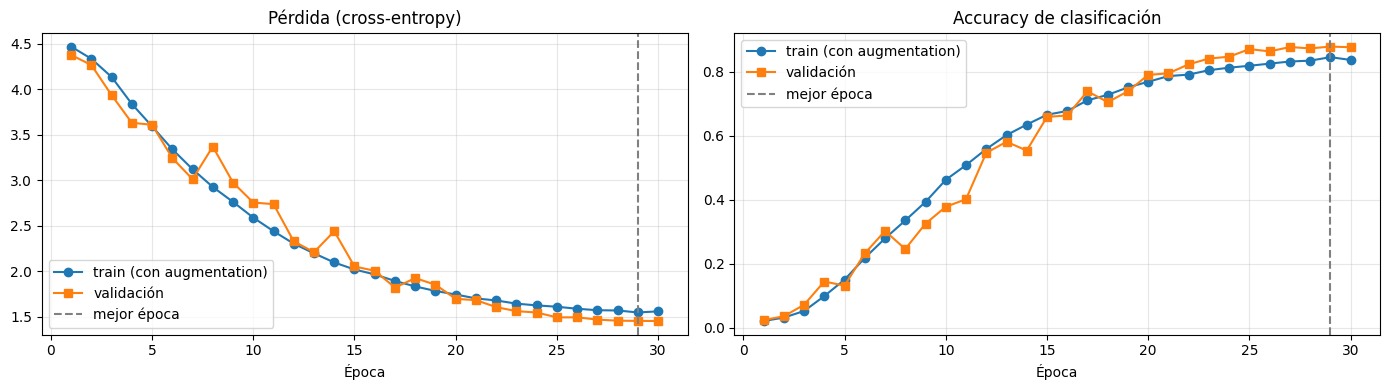

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metrica, titulo in [(axes[0], 'perdida', 'Pérdida (cross-entropy)'), (axes[1], 'acc', 'Accuracy de clasificación')]:
    ax.plot(historial['epoca'], historial[f'{metrica}_train'], 'o-', label='train (con augmentation)')
    ax.plot(historial['epoca'], historial[f'{metrica}_val'], 's-', label='validación')
    ax.axvline(mejor['epoca'], color='gray', ls='--', label='mejor época')
    ax.set_xlabel('Época'); ax.set_title(titulo); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Resultado:** las curvas de train y validación **bajan (pérdida) y suben (accuracy) juntas** durante todo el entrenamiento, sin que se separen: **no hay overfitting**. Si lo hubiera, la curva de validación se estancaría o empeoraría mientras la de train sigue mejorando.

- **Épocas 1–3:** aprendizaje lento; la red recién empieza a distinguir rasgos.
- **Épocas 4–15:** mejora rápida, con oscilaciones en validación (picos en las épocas 8 y 14) por el learning rate todavía alto.
- **Épocas 15–30:** las curvas se suavizan a medida que el scheduler reduce el learning rate, y validación queda levemente por encima de train (efecto de la augmentation y el dropout, que solo actúan en entrenamiento).
- Al final las curvas se aplanan pero siguen subiendo levemente: el modelo está cerca de su capacidad máxima con esta arquitectura y estos datos.

### 2.5 Exportación a ONNX
Se exporta **solo la parte que genera el embedding** (sin el clasificador), con la normalización L2 incluida. ONNX es el formato recomendado por el enunciado: la app lo carga con `onnxruntime` sin necesitar el código de la clase. Se verifica que el modelo exportado da los mismos embeddings que PyTorch.

In [7]:
class ExtractorEmbedding(nn.Module):
    # Lo que usa la app: imagen preprocesada -> embedding normalizado L2 (sin el clasificador)
    def __init__(self, modelo):
        super().__init__(); self.modelo = modelo
    def forward(self, x):
        return F.normalize(self.modelo.extraer_embedding(x), dim=1)

ARCH_ONNX_A = f'{MODELOS}/cnn_propia.onnx'
extractor_a = ExtractorEmbedding(modelo_a).eval().cpu()
torch.onnx.export(extractor_a, torch.randn(1, 3, 112, 112), ARCH_ONNX_A, input_names=['imagen'], output_names=['embedding'],
                  dynamic_axes={'imagen': {0: 'lote'}, 'embedding': {0: 'lote'}}, opset_version=17, dynamo=False)

# Verificación: onnxruntime (lo que usa la app) da lo mismo que PyTorch
prueba = [caras_alineadas[i] for i in por_split['val']['idx_cara'].astype(int)[:8]]
emb_onnx = fp.calcular_embeddings(fp.cargar_reconocedor(ARCH_ONNX_A), prueba)
with torch.no_grad():
    emb_torch = extractor_a(torch.from_numpy(np.concatenate([fp.preprocesar(c) for c in prueba]))).numpy()
modelo_a.to(dispositivo)  # vuelve a la GPU para la evaluación
print(f'Exportado: {ARCH_ONNX_A} ({os.path.getsize(ARCH_ONNX_A) / 1e6:.1f} MB) | embedding de {emb_onnx.shape[1]} dimensiones')
print(f'Diferencia máxima ONNX vs. PyTorch: {np.abs(emb_onnx - emb_torch).max():.1e}')

/tmp/ipykernel_9975/3097617736.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(extractor_a, torch.randn(1, 3, 112, 112), ARCH_ONNX_A, input_names=['imagen'], output_names=['embedding'],


Exportado: /content/drive/MyDrive/TP_FaceRec/models/cnn_propia.onnx (4.8 MB) | embedding de 128 dimensiones
Diferencia máxima ONNX vs. PyTorch: 2.3e-07


**Resultado:** el modelo se exportó a `cnn_propia.onnx` (**4,8 MB**), con un embedding de **128 dimensiones**. La diferencia máxima entre los embeddings de onnxruntime (lo que usa la app) y los de PyTorch es de **2,3e-07**, un error numérico despreciable: el modelo exportado es equivalente al original.

El aviso de PyTorch indica que en las versiones recientes cambió el exportador ONNX por defecto. Se usa a propósito el exportador clásico (`dynamo=False`), estable para este tipo de redes convolucionales.

## 3. Modelo B: ArcFace (InsightFace `buffalo_l`)
| | |
|---|---|
| Detector | SCRFD (`det_10g.onnx`), el mismo que se usó para alinear |
| Reconocedor | **ArcFace** con backbone **ResNet-50** (`w600k_r50.onnx`) |
| Datos de entrenamiento | **WebFace600K**: unas 600.000 identidades y millones de imágenes de internet |
| Pérdida | **ArcFace** (margen angular aditivo): fuerza a que las caras de una misma persona queden agrupadas con un margen respecto de las demás, en lugar de solo clasificarlas |
| Embedding | **512 dimensiones**, normalizado L2 |
| Licencia | Uso no comercial / investigación |

Se usa **sin reentrenar**, como extractor de embeddings. Los embeddings de todas las caras ya se calcularon en la notebook 1 (sección 3.3) con el mismo modelo. Ambos modelos se evalúan sobre **exactamente los mismos splits** y con las mismas métricas.

### 3.1 Embeddings de evaluación
Para la CNN propia se usa solo el extractor (sin el clasificador), con embeddings normalizados L2, igual que en la app.

In [8]:
@torch.no_grad()
def embeddings_cnn(tabla, lote=256):
    extractor = ExtractorEmbedding(modelo_a).eval().to(dispositivo)
    cargador = DataLoader(CarasDataset(tabla), batch_size=lote, num_workers=2)
    return np.concatenate([extractor(x.to(dispositivo)).cpu().numpy() for x, _ in cargador])

EMB = {}  # EMB[modelo][split] -> (n, d) normalizados L2
for s in ['val', 'test_closed', 'test_open']:
    EMB.setdefault('CNN propia', {})[s] = embeddings_cnn(por_split[s])
    EMB.setdefault('ArcFace', {})[s] = emb_arcface_todas[por_split[s]['idx_cara'].astype(int)]
MODELOS_CMP = ['CNN propia', 'ArcFace']
for m in MODELOS_CMP:
    print(f'{m:10s}: ' + ' | '.join(f'{s} {EMB[m][s].shape}' for s in EMB[m]))

CNN propia: val (1387, 128) | test_closed (1387, 128) | test_open (3020, 128)
ArcFace   : val (1387, 512) | test_closed (1387, 512) | test_open (3020, 512)


**Resultado:** se obtuvieron los embeddings de ambos modelos sobre los mismos tres conjuntos (validación 1.387, test closed-set 1.387 y test open-set 3.020 imágenes). La CNN propia genera vectores de **128 dimensiones** y ArcFace de **512**, todos normalizados L2.

## 4. Evaluación

### 4.1 Verificación: ¿son la misma persona?
Sobre el **test open-set** (20 personas que la CNN nunca vio) se forman pares de imágenes:
- **Positivos:** dos fotos de la misma persona.
- **Negativos:** dos fotos de personas distintas, en la misma cantidad que los positivos (pares balanceados).

Para cada par se calcula la similitud coseno, y se reportan:
- **Curva ROC y AUC:** qué tan bien separa el modelo los pares positivos de los negativos para todos los umbrales posibles (AUC = 1 es separación perfecta, 0,5 es azar).
- **EER (Equal Error Rate):** el error en el punto donde la tasa de falsas aceptaciones es igual a la de falsos rechazos. Cuanto más bajo, mejor.
- **TAR @ FAR:** qué porcentaje de pares de la misma persona se acepta (TAR) cuando solo se permite aceptar por error al 1% (FAR = 1e-2) o al 0,1% (FAR = 1e-3) de los pares de personas distintas.

Los mismos pares se arman también sobre validación, para calibrar el umbral (4.3).

In [9]:
from sklearn.metrics import roc_curve, auc

def pares(tabla, n_max=200_000, semilla=42):
    """Todos los pares positivos (misma persona) hasta n_max y la misma cantidad de negativos al azar."""
    r = np.random.default_rng(semilla)
    y = tabla['identidad'].to_numpy()
    i, j = np.triu_indices(len(y), k=1)
    pos = np.where(y[i] == y[j])[0]
    pos = r.choice(pos, min(n_max, len(pos)), replace=False)
    neg = r.choice(np.where(y[i] != y[j])[0], len(pos), replace=False)
    sel = np.concatenate([pos, neg])
    return i[sel], j[sel], np.r_[np.ones(len(pos)), np.zeros(len(neg))].astype(int)

PARES = {s: pares(por_split[s]) for s in ['val', 'test_open']}
SIMS = {m: {s: (EMB[m][s][PARES[s][0]] * EMB[m][s][PARES[s][1]]).sum(1) for s in PARES} for m in MODELOS_CMP}
for s in PARES:
    print(f'{s}: {PARES[s][2].sum():,} pares positivos y {(PARES[s][2] == 0).sum():,} negativos')

def metricas_verificacion(sims, y):
    far, tar, umbrales = roc_curve(y, sims)  # FAR = falsos positivos / negativos, TAR = verdaderos positivos / positivos
    i_eer = np.nanargmin(np.abs((1 - tar) - far))
    return dict(far=far, tar=tar, umbrales=umbrales, AUC=auc(far, tar), EER=(far[i_eer] + 1 - tar[i_eer]) / 2,
                **{f'TAR@FAR={f:g}': np.interp(f, far, tar) for f in [1e-2, 1e-3]})

VER = {m: metricas_verificacion(SIMS[m]['test_open'], PARES['test_open'][2]) for m in MODELOS_CMP}
print(pd.DataFrame({m: {k: v for k, v in VER[m].items() if k not in ('far', 'tar', 'umbrales')} for m in MODELOS_CMP}).round(4).to_string())

val: 11,104 pares positivos y 11,104 negativos
test_open: 200,000 pares positivos y 200,000 negativos
               CNN propia  ArcFace
AUC                0.8679   1.0000
EER                0.2146   0.0025
TAR@FAR=0.01       0.2714   0.9991
TAR@FAR=0.001      0.0937   0.9961


**Resultado (verificación sobre el test open-set, 200.000 pares positivos y 200.000 negativos):**
| Métrica | CNN propia | ArcFace |
|---|---|---|
| AUC | 0,868 | **≈ 1,000** |
| EER | 21,5% | **0,25%** |
| TAR @ FAR = 1e-2 | 27,1% | **99,9%** |
| TAR @ FAR = 1e-3 | 9,4% | **99,6%** |

**Interpretación:**
- **La CNN propia generaliza a personas que nunca vio** (AUC de 0,87, bastante mejor que el azar, 0,5): aprendió rasgos faciales útiles, no solo a memorizar a las 85 personas de entrenamiento.
- Pero su separación es **mucho más débil que la de ArcFace**. Con su umbral de EER se equivoca en 1 de cada 5 pares. Y si se le exige equivocarse poco (aceptar por error solo al 0,1% de los pares de personas distintas), reconoce correctamente apenas el **9%** de los pares de la misma persona.
- **ArcFace** separa casi perfectamente: con el mismo nivel de exigencia acepta el **99,6%** de los pares correctos.
- Las métricas a FAR bajo (1e-3) son las más relevantes para la app, porque aceptar a una persona como si fuera otra es el error más grave.

*Nota:* en validación hay 11.104 pares de cada tipo (menos que en test, porque validación tiene unas 16 fotos por persona). Alcanza para calibrar el umbral, aunque a FAR = 1e-3 la estimación se basa en pocos pares negativos (~11).

### 4.2 Curva ROC e histogramas de similitud
Si el modelo es bueno, el histograma de pares de la misma persona (verde) y el de personas distintas (rojo) deberían estar separados.

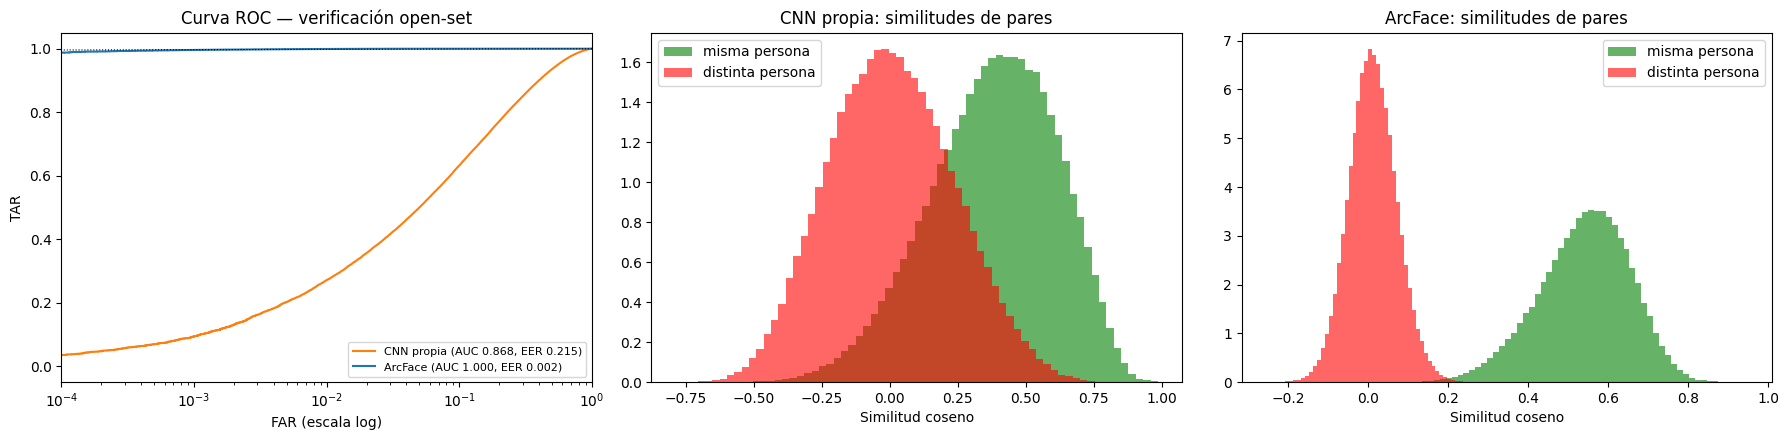

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for m, color in zip(MODELOS_CMP, ['tab:orange', 'tab:blue']):
    axes[0].plot(VER[m]['far'], VER[m]['tar'], color=color, label=f'{m} (AUC {VER[m]["AUC"]:.3f}, EER {VER[m]["EER"]:.3f})')
axes[0].plot([0, 1], [0, 1], 'k:', lw=0.8); axes[0].set_xscale('log'); axes[0].set_xlim(1e-4, 1)
axes[0].set_xlabel('FAR (escala log)'); axes[0].set_ylabel('TAR'); axes[0].set_title('Curva ROC — verificación open-set'); axes[0].legend(fontsize=8)
for ax, m in zip(axes[1:], MODELOS_CMP):
    y = PARES['test_open'][2]
    ax.hist(SIMS[m]['test_open'][y == 1], bins=60, alpha=0.6, color='green', label='misma persona', density=True)
    ax.hist(SIMS[m]['test_open'][y == 0], bins=60, alpha=0.6, color='red', label='distinta persona', density=True)
    ax.set_xlabel('Similitud coseno'); ax.set_title(f'{m}: similitudes de pares'); ax.legend()
plt.tight_layout(); plt.show()

**Resultado:**
- **Curva ROC:** la de ArcFace está pegada al borde superior (TAR ≈ 1 aun con FAR = 1e-4), mientras que la de la CNN propia recién alcanza valores altos de TAR cuando se aceptan muchos falsos positivos.
- **Histogramas de la CNN propia:** las distribuciones de "misma persona" (verde, centrada en ≈ 0,45) y "distinta persona" (roja, centrada en ≈ 0) están **muy superpuestas**. En la zona marrón, entre 0 y 0,5 aproximadamente, **ningún umbral puede separar** bien los pares: cualquier valor que se elija deja pasar personas distintas o rechaza a la misma persona.
- **Histogramas de ArcFace:** las dos distribuciones están **claramente separadas**. Las personas distintas se concentran en ≈ 0 (sus embeddings son casi perpendiculares) y la misma persona en ≈ 0,55, con una superposición mínima alrededor de 0,2. Un umbral en esa zona separa casi perfectamente.

**Por qué la diferencia:** la CNN propia se entrenó solo para clasificar 85 personas con softmax, que separa las clases conocidas pero **no obliga a dejar un margen** entre ellas. Con personas nuevas, los embeddings quedan "a mitad de camino". ArcFace se entrenó con una pérdida de **margen angular** sobre unas 600.000 identidades: aprendió explícitamente a juntar a la misma persona y alejar a las distintas, y eso **generaliza a personas nunca vistas**.

### 4.3 Calibración del umbral (con validación)
La app decide "persona conocida" o `unknown` comparando la similitud con `SIMILARITY_THRESHOLD`. El umbral se calibra con los pares de **validación**, no con los de test, para que las métricas de test no estén "optimistas".

Se comparan dos criterios:
- **FAR = 1e-3:** el umbral más bajo que acepta por error a lo sumo 1 de cada 1.000 pares de personas distintas. Prioriza **no confundir a una persona con otra**, el error más grave en un sistema de reconocimiento.
- **EER:** el punto donde la tasa de falsas aceptaciones (FAR) es igual a la de falsos rechazos (FRR).

Para ArcFace, validación funciona como un conjunto de personas no vistas (nunca se entrenó con Pins). Para la CNN propia, en cambio, las personas de validación sí fueron vistas en el entrenamiento, así que su umbral puede quedar algo optimista al aplicarlo a personas nuevas.

Luego se verifica qué FAR y TAR produce cada umbral sobre el test open-set.

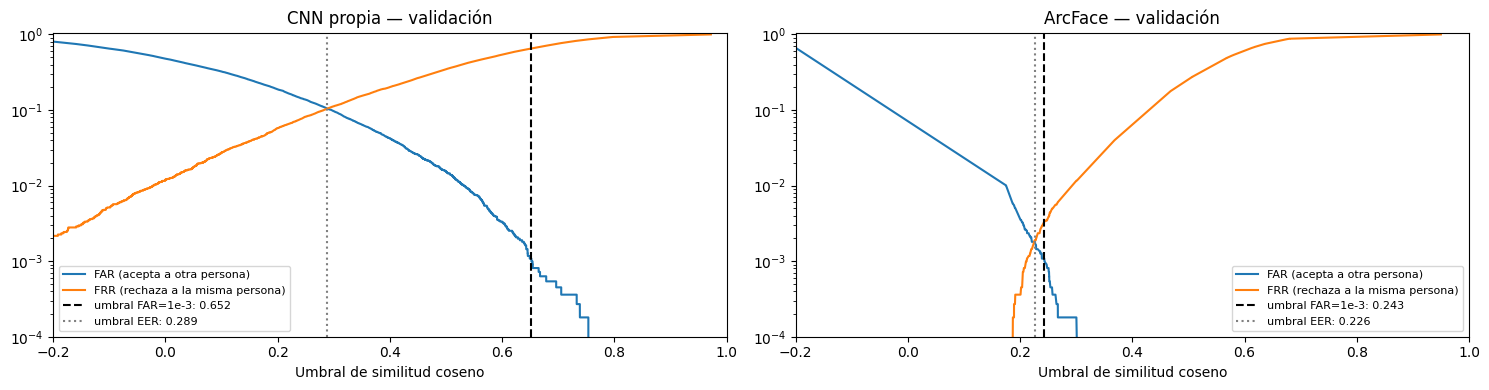

Umbrales calibrados en validación y su efecto en test open-set:
  CNN propia | FAR=1e-3: umbral 0.652 → en test: FAR 0.0016, TAR 0.118
  CNN propia | EER     : umbral 0.289 → en test: FAR 0.1178, TAR 0.665
  ArcFace    | FAR=1e-3: umbral 0.243 → en test: FAR 0.0002, TAR 0.991
  ArcFace    | EER     : umbral 0.226 → en test: FAR 0.0005, TAR 0.994


In [11]:
FAR_OBJETIVO = 1e-3
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
UMBRAL = {}
for ax, m in zip(axes, MODELOS_CMP):
    v = metricas_verificacion(SIMS[m]['val'], PARES['val'][2])
    far, frr, u = v['far'][1:], 1 - v['tar'][1:], v['umbrales'][1:]  # se descarta el primer umbral (infinito)
    UMBRAL[m] = {'FAR=1e-3': u[np.where(far <= FAR_OBJETIVO)[0][-1]],  # el umbral más bajo que cumple FAR <= 1e-3
                 'EER': u[np.argmin(np.abs(far - frr))]}                # donde FAR = FRR
    ax.plot(u, far, label='FAR (acepta a otra persona)'); ax.plot(u, frr, label='FRR (rechaza a la misma persona)')
    ax.axvline(UMBRAL[m]['FAR=1e-3'], color='k', ls='--', label=f'umbral FAR=1e-3: {UMBRAL[m]["FAR=1e-3"]:.3f}')
    ax.axvline(UMBRAL[m]['EER'], color='gray', ls=':', label=f'umbral EER: {UMBRAL[m]["EER"]:.3f}')
    ax.set_yscale('log'); ax.set_ylim(1e-4, 1.05); ax.set_xlim(-0.2, 1)
    ax.set_xlabel('Umbral de similitud coseno'); ax.set_title(f'{m} — validación'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Umbrales calibrados en validación y su efecto en test open-set:')
for m in MODELOS_CMP:
    s, y = SIMS[m]['test_open'], PARES['test_open'][2]
    for nombre, u in UMBRAL[m].items():
        print(f'  {m:10s} | {nombre:8s}: umbral {u:.3f} → en test: FAR {(s[y == 0] >= u).mean():.4f}, TAR {(s[y == 1] >= u).mean():.3f}')

**Resultado:**
| Modelo | Criterio | Umbral (val) | FAR en test open-set | TAR en test open-set |
|---|---|---|---|---|
| CNN propia | FAR = 1e-3 | 0,652 | 0,16% | 11,8% |
| CNN propia | EER | 0,289 | 11,8% | 66,5% |
| **ArcFace** | **FAR = 1e-3** | **0,243** | **0,02%** | **99,1%** |
| ArcFace | EER | 0,226 | 0,05% | 99,4% |

**Interpretación:**
- **ArcFace:** las curvas de FAR y FRR se cruzan en un valor muy bajo (≈ 0,2%), y el umbral elegido en validación **se mantiene en test**: con 0,243 acepta por error solo el 0,02% de los pares de personas distintas y reconoce el 99,1% de los pares de la misma persona.
- **CNN propia:** no existe un umbral que sea bueno en ambos errores. Para cumplir FAR = 1e-3 necesita un umbral muy alto (0,652) y entonces rechaza al 88% de los pares de la misma persona. Además, **en test su FAR (0,16%) supera el objetivo (0,1%)**, porque se calibró con personas que vio en el entrenamiento: el umbral queda optimista frente a personas nuevas, como se anticipó.

**Umbral elegido para la app:** `SIMILARITY_THRESHOLD = 0.243` con ArcFace y métrica coseno.
- Se elige el criterio **FAR = 1e-3** porque en la app el error más grave es **identificar a una persona como otra**, y prácticamente no tiene costo: el TAR (99,1%) es casi igual al del EER (99,4%).
- El valor por defecto de la plantilla (0,55) sería demasiado exigente: según el histograma de 4.2, rechazaría aproximadamente a la mitad de las fotos de personas registradas.

### 4.4 Identificación: ¿quién es?
Se simula el uso real de la app sobre el test open-set:
- **Galería** (lo que se registra con `/insert`): 5 fotos de cada una de **15 personas**.
- **Personas desconocidas:** las otras **5 personas no se registran**. Sus fotos deberían devolver `unknown`.
- **Consultas** (lo que llega a `/predict`): todas las fotos que no están en la galería.

Para cada consulta se busca la foto de la galería más parecida, igual que `identify()` en la app. Si la similitud no supera el umbral calibrado (FAR = 1e-3), la respuesta es `unknown`.

Métricas:
- **Top-1 / Top-5** (personas registradas, sin umbral): si la persona correcta es la más parecida, o está entre las 5 más parecidas.
- **Precision, recall y F1 macro:** con el umbral aplicado y `unknown` como una clase más; "macro" promedia todas las personas por igual.
- **Desconocidos rechazados:** porcentaje de fotos de personas no registradas que se responden correctamente como `unknown`.
- **Conocidos rechazados por error:** porcentaje de fotos de personas registradas que quedaron como `unknown`.

In [12]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

N_GALERIA, N_DESCONOCIDOS = 5, 5
r = np.random.default_rng(42)
ids_open = np.sort(por_split['test_open']['identidad'].unique())
ids_desconocidos = r.choice(ids_open, N_DESCONOCIDOS, replace=False)   # nunca se registran: deberían dar "unknown"
ids_registrados = np.setdiff1d(ids_open, ids_desconocidos)
t_open = por_split['test_open']
es_galeria = np.zeros(len(t_open), bool)
for ident in ids_registrados:  # 5 fotos por persona registrada, como hace el /insert de la app
    es_galeria[r.choice(np.where(t_open['identidad'] == ident)[0], N_GALERIA, replace=False)] = True
y_consulta = t_open['identidad'].to_numpy()[~es_galeria]
y_real = np.where(np.isin(y_consulta, ids_desconocidos), 'unknown', y_consulta)
print(f'Galería: {es_galeria.sum()} fotos de {len(ids_registrados)} personas | consultas: {len(y_consulta)} '
      f'({np.isin(y_consulta, ids_desconocidos).sum()} de {N_DESCONOCIDOS} personas desconocidas)')
print(f'Personas desconocidas (no registradas): {", ".join(ids_desconocidos)}')

IDENT = {}
for m in MODELOS_CMP:
    E = EMB[m]['test_open']; G, y_gal = E[es_galeria], t_open['identidad'].to_numpy()[es_galeria]
    sims = E[~es_galeria] @ G.T
    # Mejor similitud por identidad registrada (igual que identify() de la app: el registro más parecido)
    por_id = np.stack([sims[:, y_gal == ident].max(1) for ident in ids_registrados], axis=1)
    orden = np.argsort(-por_id, axis=1)
    mejor, score = ids_registrados[orden[:, 0]], por_id.max(1)
    pred = np.where(score >= UMBRAL[m]['FAR=1e-3'], mejor, 'unknown')
    conocidos = y_real != 'unknown'
    top1 = (mejor[conocidos] == y_real[conocidos]).mean()
    top5 = np.mean([y in ids_registrados[o[:5]] for y, o in zip(y_real[conocidos], orden[conocidos])])
    p, rc, f1, _ = precision_recall_fscore_support(y_real, pred, average='macro', zero_division=0)
    IDENT[m] = dict(pred=pred, **{'Top-1 (sin umbral)': top1, 'Top-5 (sin umbral)': top5,
                    'Accuracy con umbral': (pred == y_real).mean(), 'Precision macro': p, 'Recall macro': rc, 'F1 macro': f1,
                    'Desconocidos rechazados': (pred[~conocidos] == 'unknown').mean(),
                    'Conocidos rechazados por error': (pred[conocidos] == 'unknown').mean()})
print(pd.DataFrame({m: {k: v for k, v in IDENT[m].items() if k != 'pred'} for m in MODELOS_CMP}).round(3).to_string())

Galería: 75 fotos de 15 personas | consultas: 2945 (871 de 5 personas desconocidas)
Personas desconocidas (no registradas): Robert Downey Jr, Maria Pedraza, Rami Malek, Avril Lavigne, elizabeth olsen
                                CNN propia  ArcFace
Top-1 (sin umbral)                   0.658    1.000
Top-5 (sin umbral)                   0.947    1.000
Accuracy con umbral                  0.515    0.997
Precision macro                      0.746    0.996
Recall macro                         0.414    0.999
F1 macro                             0.478    0.998
Desconocidos rechazados              0.873    0.991
Conocidos rechazados por error       0.586    0.000


**Resultado (identificación en test open-set: galería de 15 personas con 5 fotos cada una, 2.945 consultas, de las cuales 871 son de 5 personas no registradas):**
| Métrica | CNN propia | ArcFace |
|---|---|---|
| Top-1 (sin umbral) | 65,8% | **100%** |
| Top-5 (sin umbral) | 94,7% | **100%** |
| Accuracy con umbral | 51,5% | **99,7%** |
| Precision / Recall / F1 macro | 0,75 / 0,41 / 0,48 | **0,996 / 0,999 / 0,998** |
| Desconocidos rechazados | 87,3% | **99,1%** |
| Conocidos rechazados por error | 58,6% | **0%** |

**Interpretación:**
- **ArcFace** identifica correctamente a todas las personas registradas (Top-1 = 100%) y rechaza como `unknown` al 99,1% de las fotos de personas no registradas. Solo un 0,9% de las fotos de desconocidos se confunde con alguien de la galería.
- **CNN propia:** sin umbral, acierta el 65,8% de las veces entre 15 personas (el azar sería 6,7%), y la persona correcta está entre las 5 más parecidas en el 94,7%. **Aprendió algo útil, pero no lo suficiente.** Al aplicar el umbral exigente, rechaza al 58,6% de las personas registradas: el umbral que evita confusiones es tan alto que también deja afuera a la mayoría de los aciertos. Esto confirma que sus distribuciones de similitud están demasiado superpuestas (4.2).
- La **precision macro (0,75) es mayor que el recall (0,41)** en la CNN: cuando se anima a nombrar a alguien suele acertar, pero la mayoría de las veces responde `unknown`.

### 4.5 Matrices de confusión
Filas: persona real. Columnas: predicción (incluye `unknown`). Cada fila suma 1. En un modelo perfecto, toda la masa está en la diagonal, y la fila `unknown` (personas no registradas) cae en la columna `unknown`.

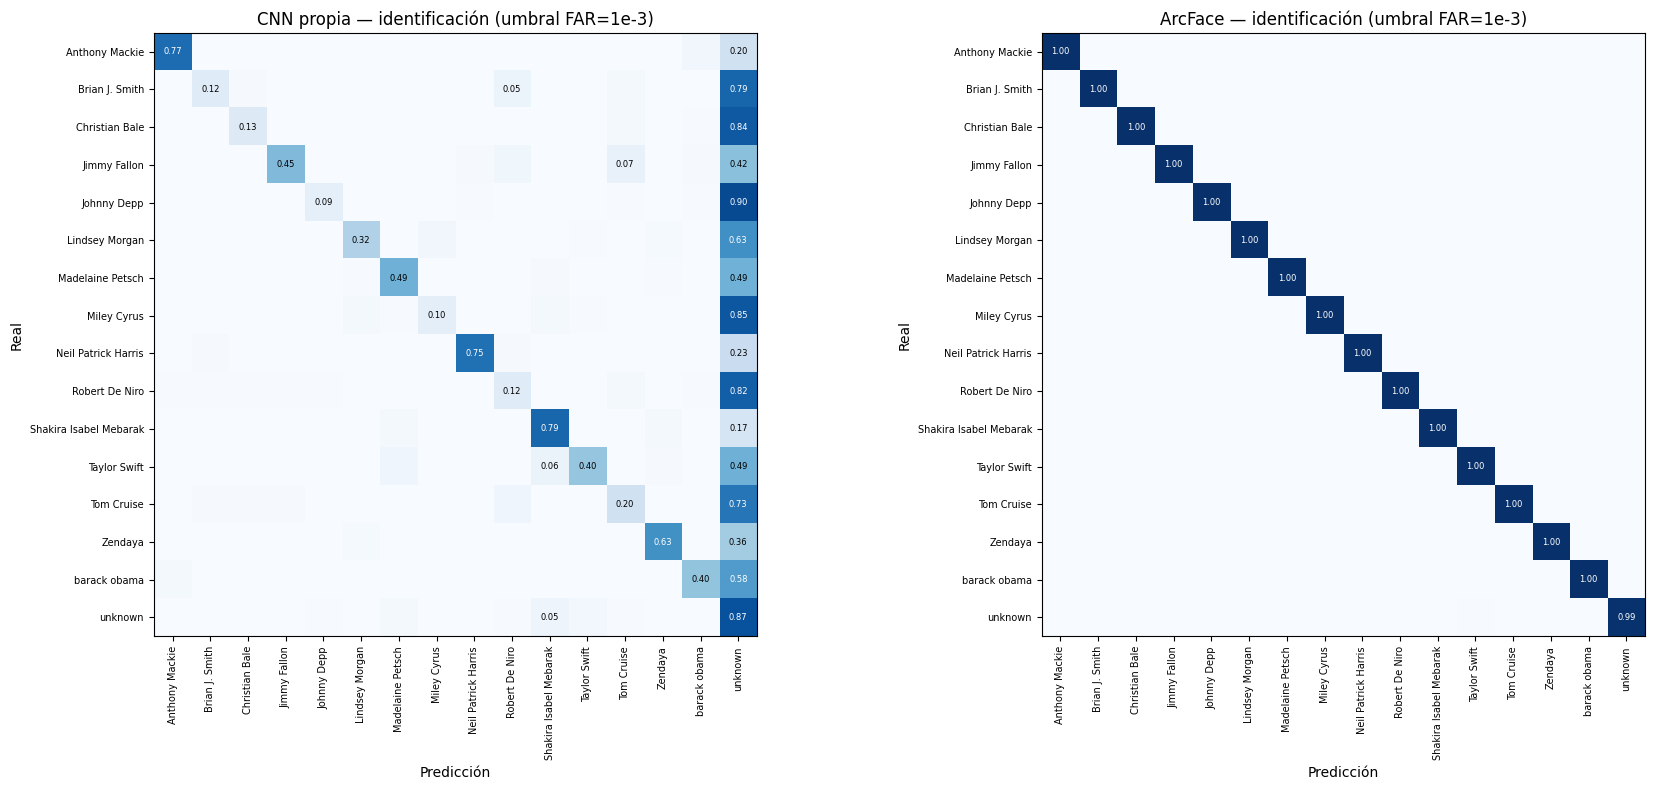

In [13]:
etiq = list(ids_registrados) + ['unknown']
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, m in zip(axes, MODELOS_CMP):
    cm = confusion_matrix(y_real, IDENT[m]['pred'], labels=etiq, normalize='true')
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(etiq))); ax.set_xticklabels(etiq, rotation=90, fontsize=7)
    ax.set_yticks(range(len(etiq))); ax.set_yticklabels(etiq, fontsize=7)
    for i in range(len(etiq)):
        for j in range(len(etiq)):
            if cm[i, j] >= 0.05: ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if cm[i, j] > 0.5 else 'black')
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real'); ax.set_title(f'{m} — identificación (umbral FAR=1e-3)')
plt.tight_layout(); plt.show()

**Resultado:**
- **ArcFace:** la matriz es prácticamente una **diagonal perfecta**. Cada persona registrada se identifica correctamente el 100% de las veces, y el 99% de las fotos de personas no registradas se responde como `unknown`.
- **CNN propia:** casi no confunde a una persona con otra. Las confusiones cruzadas son pocas y bajas, como Taylor Swift → Shakira (6%) o Jimmy Fallon → Tom Cruise (7%). Su error principal es **responder `unknown`** (la última columna concentra la mayor parte de la masa), consecuencia del umbral exigente que necesita para no confundir personas.

**Diferencias entre identidades en la CNN:**
- **Mejor reconocidas:** Shakira (79%), Anthony Mackie (77%) y Neil Patrick Harris (75%).
- **Peor reconocidas:** Johnny Depp (9%), Miley Cyrus (10%), Brian J. Smith y Robert De Niro (12%), Christian Bale (13%).

**Hipótesis:** las peor reconocidas son personas con **gran variación de apariencia** entre fotos: caracterizaciones para películas (Johnny Depp, Christian Bale, que cambia mucho de peso), cambios de estilo (Miley Cyrus) o fotos en edades muy distintas (Robert De Niro, que ya mostraba dos sub-grupos en el clustering de la notebook 1). Una red chica entrenada con pocos datos se apoya en rasgos más "superficiales" (peinado, color de piel, tono de la foto), que cambian entre fotos. En cambio, las mejor reconocidas pueden tener rasgos más constantes o distintivos dentro del dataset. Esto último también es un riesgo de **sesgo**: si un rasgo como el tono de piel es poco frecuente en el dataset, el modelo puede usarlo como atajo en vez de aprender la identidad.

### 4.6 Clustering de los embeddings (test open-set)
Se comparan los embeddings de ambos modelos para las 20 personas que la CNN nunca vio: proyección t-SNE coloreada por identidad, silhouette (con las identidades reales) y K-Means con k = 20 comparado con las identidades (ARI y NMI).

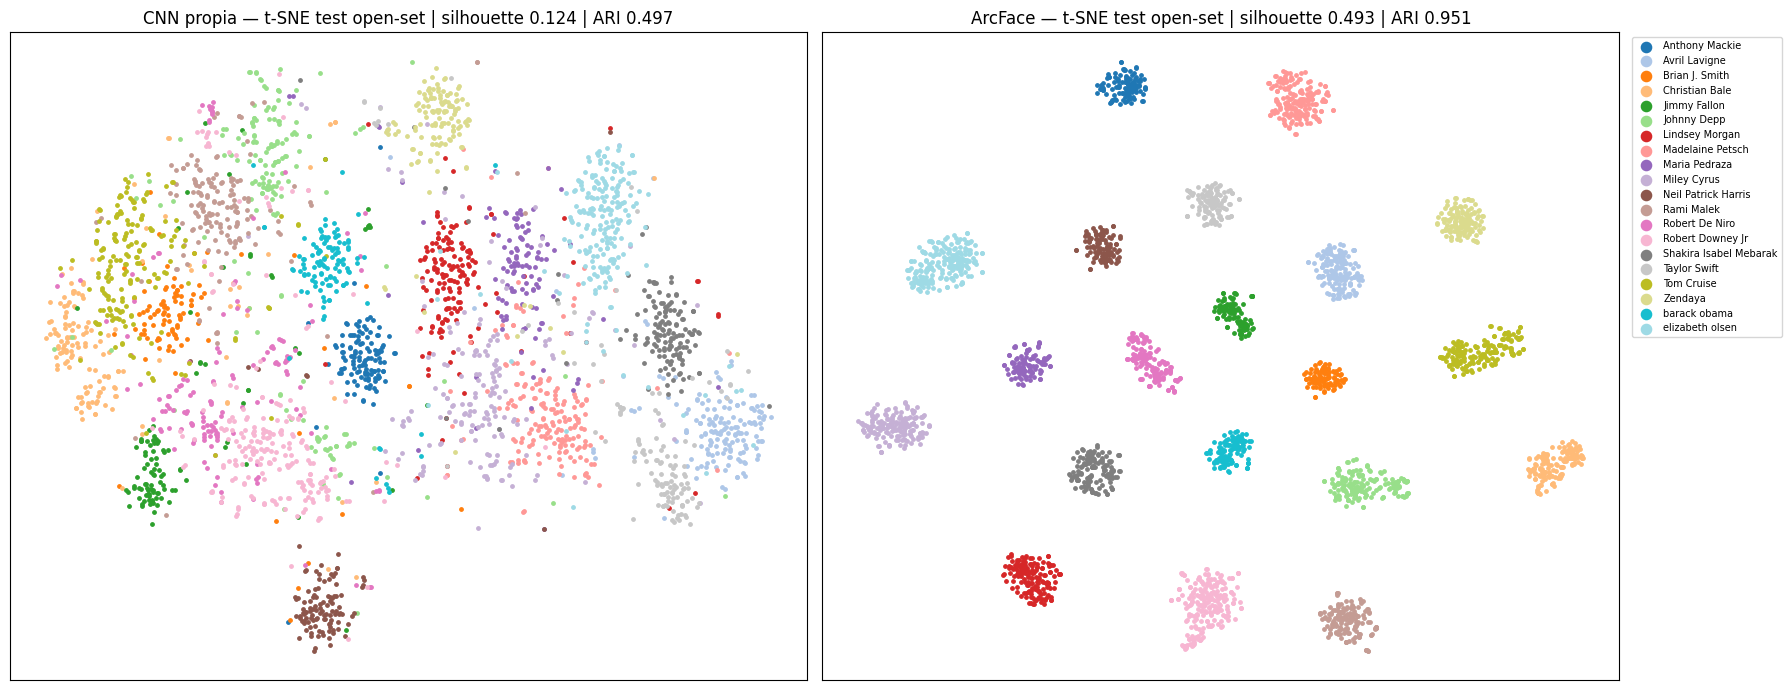

               CNN propia  ArcFace
Silhouette          0.124    0.493
ARI (K-Means)       0.497    0.951
NMI (K-Means)       0.639    0.985


In [14]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

y_open = t_open['identidad'].to_numpy()
CLUST = {}
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colores = plt.cm.tab20(np.linspace(0, 1, len(ids_open)))
for ax, m in zip(axes, MODELOS_CMP):
    E = EMB[m]['test_open']
    km = KMeans(n_clusters=len(ids_open), n_init=5, random_state=42).fit(E)
    CLUST[m] = {'Silhouette': silhouette_score(E, y_open, metric='cosine'),
                'ARI (K-Means)': adjusted_rand_score(y_open, km.labels_), 'NMI (K-Means)': normalized_mutual_info_score(y_open, km.labels_)}
    e2 = TSNE(n_components=2, metric='cosine', perplexity=30, random_state=42).fit_transform(E)
    for c, ident in zip(colores, ids_open):
        ax.scatter(*e2[y_open == ident].T, s=6, color=c, label=ident)
    ax.set_title(f'{m} — t-SNE test open-set | silhouette {CLUST[m]["Silhouette"]:.3f} | ARI {CLUST[m]["ARI (K-Means)"]:.3f}')
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(fontsize=7, markerscale=3, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()
print(pd.DataFrame(CLUST).round(3).to_string())

**Resultado (clustering de los embeddings de las 20 personas nunca vistas):**
| Métrica | CNN propia | ArcFace |
|---|---|---|
| Silhouette | 0,124 | **0,493** |
| ARI (K-Means) | 0,497 | **0,951** |
| NMI (K-Means) | 0,639 | **0,985** |

**Interpretación:**
- **ArcFace:** las 20 personas forman **20 grupos compactos y bien separados**, igual que en la notebook 1. K-Means las recupera casi perfectamente (ARI 0,95). Algunos grupos alargados, como Tom Cruise o Johnny Depp, reflejan variación de edad o caracterización dentro de la misma persona.
- **CNN propia:** se forman grupos, pero **más dispersos y superpuestos**, sobre todo en la mitad izquierda del gráfico. Algunas identidades se separan relativamente bien (Neil Patrick Harris, Anthony Mackie, Lindsey Morgan, Jimmy Fallon), mientras otras quedan mezcladas (Christian Bale, Tom Cruise, Johnny Depp, Robert Downey Jr). Es coherente con la matriz de confusión: las identidades más separadas en el t-SNE son las mejor reconocidas.
- La CNN **sí aprendió a agrupar caras de personas que nunca vio** (ARI de 0,50, frente a ≈ 0 que daría el azar): esto confirma que el embedding generaliza en parte. Pero los grupos no son lo bastante compactos para un umbral confiable.

### 4.7 Análisis de errores
Para cada modelo, con su umbral calibrado (FAR = 1e-3), se muestran:
- **Falsos positivos:** pares de **personas distintas** con la similitud más alta (aceptados como la misma persona).
- **Falsos negativos:** pares de **la misma persona** con la similitud más baja (rechazados).

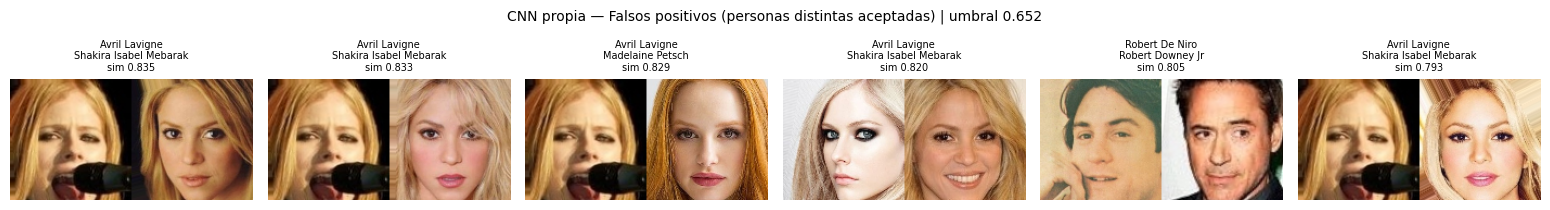

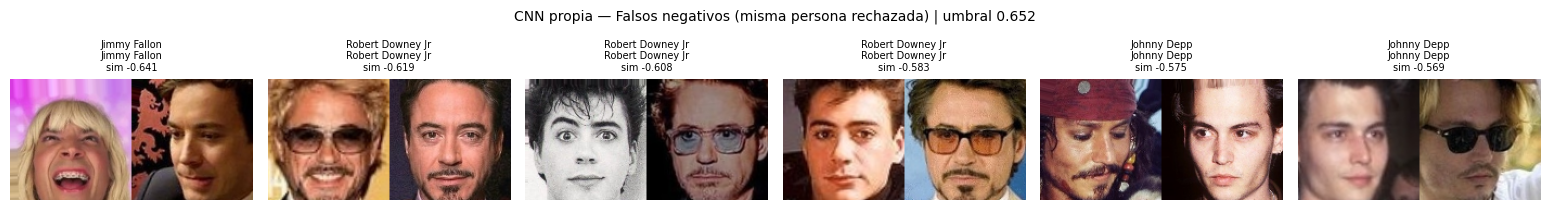

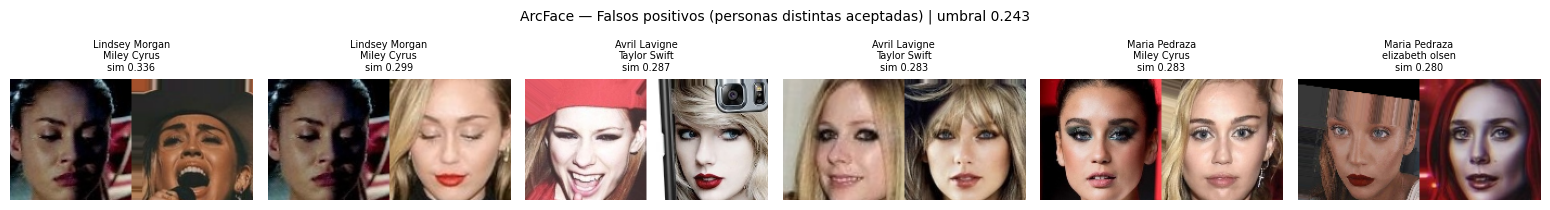

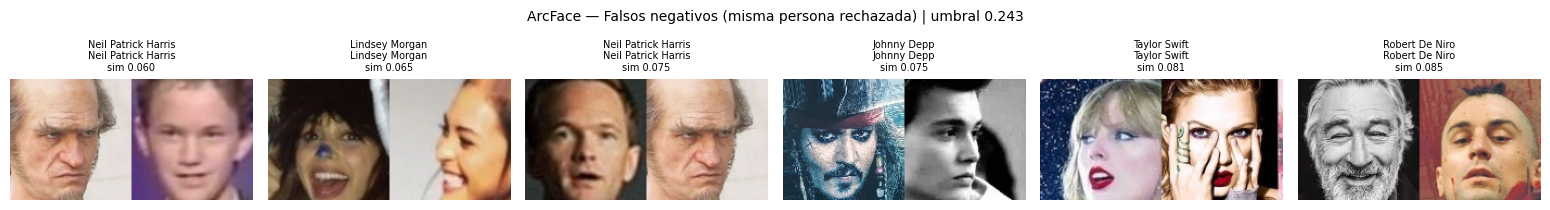

In [15]:
def mostrar_pares(m, tipo, n=6):
    s, (i, j, y) = SIMS[m]['test_open'], PARES['test_open']
    u = UMBRAL[m]['FAR=1e-3']
    if tipo == 'FP':  # personas distintas aceptadas como la misma: los negativos con MAYOR similitud
        cand = np.where((y == 0) & (s >= u))[0]; cand = cand[np.argsort(-s[cand])][:n]
    else:             # misma persona rechazada: los positivos con MENOR similitud
        cand = np.where((y == 1) & (s < u))[0]; cand = cand[np.argsort(s[cand])][:n]
    if len(cand) == 0:
        print(f'{m}: no hay {tipo} con el umbral {u:.3f}'); return
    fig, axes = plt.subplots(1, len(cand), figsize=(2.6 * len(cand), 2.4), squeeze=False)
    for ax, k in zip(axes[0], cand):
        a, b = t_open.iloc[i[k]], t_open.iloc[j[k]]
        par = np.hstack([caras_alineadas[int(a['idx_cara'])], caras_alineadas[int(b['idx_cara'])]])
        ax.imshow(cv2.cvtColor(par, cv2.COLOR_BGR2RGB)); ax.axis('off')
        ax.set_title(f'{a["identidad"]}\n{b["identidad"]}\nsim {s[k]:.3f}', fontsize=7)
    nombre = 'Falsos positivos (personas distintas aceptadas)' if tipo == 'FP' else 'Falsos negativos (misma persona rechazada)'
    plt.suptitle(f'{m} — {nombre} | umbral {u:.3f}', fontsize=10); plt.tight_layout(); plt.show()

for m in MODELOS_CMP:
    for tipo in ['FP', 'FN']:
        mostrar_pares(m, tipo)

**Resultado:**

**CNN propia: falsos positivos (personas distintas aceptadas, similitud de 0,79 a 0,84).**
Casi todos involucran la misma foto de Avril Lavigne (cantando, con micrófono y tono cálido) emparejada con Shakira o Madelaine Petsch: **mujeres de pelo largo rubio o pelirrojo, con iluminación cálida**. El otro caso empareja a Robert De Niro joven con Robert Downey Jr: hombres de pelo oscuro y encuadre similar. La CNN se basa en **rasgos de apariencia general** (color de pelo, tono de la foto) y no en la estructura del rostro.

**CNN propia: falsos negativos (misma persona rechazada, similitud de -0,64 a -0,57).**
Caracterizaciones (Jimmy Fallon con peluca y mueca, Johnny Depp como pirata), anteojos de sol o con cristales de color (Robert Downey Jr, Johnny Depp) y cambios de edad o de tipo de foto (Robert Downey Jr joven en blanco y negro frente a una foto actual). Los cambios de apariencia la desorientan por completo: llega a dar similitudes negativas.

**ArcFace: falsos positivos (similitud de 0,28 a 0,34, apenas por encima del umbral 0,243).**
Son **parecidos reales de estilo**: Avril Lavigne y Taylor Swift (rubias, delineado marcado, flequillo), o Maria Pedraza con Miley Cyrus y Elizabeth Olsen (maquillaje intenso). También influye la **calidad de la imagen**: una foto oscura con los ojos cerrados (Lindsey Morgan) y una cara alineada con franjas en el borde por el recorte ajustado (Maria Pedraza). Aun así, las similitudes son bajas: son casos límite y no confusiones claras.

**ArcFace: falsos negativos (similitud de 0,06 a 0,09).**
Son **casos extremos de apariencia**: Neil Patrick Harris con maquillaje protésico de anciano para un personaje frente a una foto de su infancia, Johnny Depp caracterizado como pirata, Taylor Swift con la mano tapando media cara, Robert De Niro anciano con barba frente a joven con la cabeza rapada, y Lindsey Morgan con una nariz de payaso en una foto borrosa.

**Conclusión del análisis de errores:**
- Los errores de **ArcFace** ocurren solo en casos que serían difíciles incluso para una persona: maquillaje de personaje, décadas de diferencia de edad, oclusiones grandes o gente que realmente se parece. Sus similitudes en esos casos son ambiguas (0,06 a 0,34), no errores con alta confianza.
- Los errores de la **CNN propia** son **con alta confianza** (similitudes de 0,8 entre personas distintas y negativas para la misma persona) y en casos que no son tan difíciles: confunde personas por el color de pelo y el tono de la foto. Esto confirma que aprendió rasgos superficiales en lugar de la identidad.

### 4.8 Costo computacional
Se mide sobre los archivos `.onnx` con onnxruntime en **CPU**, que es como corre la app: cantidad de parámetros, tamaño del archivo, tiempo de inferencia por rostro (promedio de 50 ejecuciones, sin contar la detección) y dimensión del embedding.

In [16]:
import onnx, onnxruntime as ort
def costo(ruta, n=50):
    sesion = ort.InferenceSession(ruta, providers=['CPUExecutionProvider'])
    x = fp.preprocesar(caras_alineadas[0]); nombre = sesion.get_inputs()[0].name
    for _ in range(5): sesion.run(None, {nombre: x})  # calentamiento
    t0 = time.perf_counter()
    for _ in range(n): sesion.run(None, {nombre: x})
    params = sum(int(np.prod(t.dims)) for t in onnx.load(ruta).graph.initializer)
    return {'Parámetros (M)': params / 1e6, 'Tamaño (MB)': os.path.getsize(ruta) / 1e6,
            'Inferencia CPU (ms/rostro)': 1000 * (time.perf_counter() - t0) / n, 'Dimensión del embedding': sesion.get_outputs()[0].shape[-1]}

COSTO = {'CNN propia': costo(ARCH_ONNX_A), 'ArcFace': costo(f'{MODELOS}/w600k_r50.onnx')}
print(pd.DataFrame(COSTO).round(2).to_string())

                            CNN propia  ArcFace
Parámetros (M)                    1.21    43.59
Tamaño (MB)                       4.83   174.38
Inferencia CPU (ms/rostro)       10.71   389.84
Dimensión del embedding         128.00   512.00


**Resultado (CPU de Colab, sin contar la detección):**
| | CNN propia | ArcFace |
|---|---|---|
| Parámetros | 1,21 M | 43,59 M (**36 veces más**) |
| Tamaño del archivo | 4,8 MB | 174,4 MB |
| Inferencia CPU | **17 ms/rostro** | 380 ms/rostro (**22 veces más lento**) |
| Dimensión del embedding | 128 | 512 |

**Interpretación:** la CNN propia es **mucho más liviana y rápida**: podría correr en tiempo real en un dispositivo modesto, y sus embeddings ocupan 4 veces menos espacio en la base de datos. ArcFace es pesado, pero para esta app el costo es aceptable: se procesa una imagen por pedido y 0,4 s por rostro (en la CPU de Colab, que es lenta; en una PC común suele ser bastante menos) no afecta la experiencia de uso. El costo computacional **no compensa** la enorme diferencia de desempeño.

### 4.9 Experimentos con la CNN propia
Para medir el aporte de la data augmentation, se entrena **la misma CNN** (misma arquitectura, hiperparámetros, semilla y datos) **sin augmentation**, y se compara con el modelo final. Solo se cambia una variable, así la diferencia en los resultados se puede atribuir a la augmentation.

Se comparan la accuracy de clasificación (personas conocidas) y la verificación sobre el **test open-set** (personas nunca vistas), que es lo que importa para la app.

In [17]:
ARCH_EXP = f'{MODELOS}/cnn_sin_aug_mejor.pth'
ARCH_EXP_HIST = f'{MODELOS}/cnn_sin_aug_historial.csv'

torch.manual_seed(42)
modelo_exp = CNNFacial(n_clases=len(ids_train)).to(dispositivo)  # misma arquitectura e hiperparámetros
cargador_sin_aug = DataLoader(CarasDataset(por_split['train'], aumentar=False), batch_size=128, shuffle=True, num_workers=2, drop_last=True)
criterio_exp = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.1)
optim_exp = torch.optim.AdamW(modelo_exp.parameters(), lr=1e-3, weight_decay=5e-4)
sched_exp = torch.optim.lr_scheduler.CosineAnnealingLR(optim_exp, T_max=EPOCAS)

def epoca_exp(cargador, entrenar):
    modelo_exp.train(entrenar)
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            logits = modelo_exp(x); perdida = criterio_exp(logits, y)
            if entrenar:
                optim_exp.zero_grad(); perdida.backward(); optim_exp.step()
            perdida_total += perdida.item() * len(y); aciertos += (logits.argmax(1) == y).sum().item(); n += len(y)
    return perdida_total / n, aciertos / n

if os.path.exists(ARCH_EXP) and os.path.exists(ARCH_EXP_HIST):
    modelo_exp.load_state_dict(torch.load(ARCH_EXP, map_location=dispositivo))
    historial_exp = pd.read_csv(ARCH_EXP_HIST)
    print('Experimento cargado desde Drive.')
    for _, h in historial_exp.iterrows():  # se muestran los logs del entrenamiento original
        print(f'Época {int(h.epoca):2d} | train: pérdida {h.perdida_train:.3f} acc {h.acc_train:.3f} | val: pérdida {h.perdida_val:.3f} acc {h.acc_val:.3f}')
else:
    filas, mejor_acc, sin_mejora = [], 0.0, 0
    for epoca in range(1, EPOCAS + 1):
        t0 = time.time()
        p_tr, a_tr = epoca_exp(cargador_sin_aug, entrenar=True)
        p_va, a_va = epoca_exp(cargador_val, entrenar=False)
        sched_exp.step()
        filas.append(dict(epoca=epoca, perdida_train=p_tr, acc_train=a_tr, perdida_val=p_va, acc_val=a_va))
        marca = ''
        if a_va > mejor_acc:
            mejor_acc, sin_mejora, marca = a_va, 0, '  ← mejor'
            torch.save(modelo_exp.state_dict(), ARCH_EXP)
        else:
            sin_mejora += 1
        print(f'Época {epoca:2d} | train: pérdida {p_tr:.3f} acc {a_tr:.3f} | val: pérdida {p_va:.3f} acc {a_va:.3f} | {time.time() - t0:.0f}s{marca}')
        if sin_mejora >= PACIENCIA:
            print(f'Early stopping: {PACIENCIA} épocas sin mejorar en validación.'); break
    historial_exp = pd.DataFrame(filas); historial_exp.to_csv(ARCH_EXP_HIST, index=False)
    modelo_exp.load_state_dict(torch.load(ARCH_EXP, map_location=dispositivo))

Experimento cargado desde Drive.
Época  1 | train: pérdida 4.314 acc 0.038 | val: pérdida 4.206 acc 0.041
Época  2 | train: pérdida 3.839 acc 0.099 | val: pérdida 3.726 acc 0.125
Época  3 | train: pérdida 3.358 acc 0.218 | val: pérdida 3.554 acc 0.166
Época  4 | train: pérdida 2.965 acc 0.335 | val: pérdida 3.012 acc 0.319
Época  5 | train: pérdida 2.630 acc 0.448 | val: pérdida 2.683 acc 0.429
Época  6 | train: pérdida 2.345 acc 0.553 | val: pérdida 3.195 acc 0.318
Época  7 | train: pérdida 2.136 acc 0.618 | val: pérdida 2.308 acc 0.558
Época  8 | train: pérdida 1.945 acc 0.688 | val: pérdida 2.339 acc 0.559
Época  9 | train: pérdida 1.792 acc 0.746 | val: pérdida 2.231 acc 0.607
Época 10 | train: pérdida 1.663 acc 0.797 | val: pérdida 2.156 acc 0.629
Época 11 | train: pérdida 1.539 acc 0.847 | val: pérdida 2.365 acc 0.564
Época 12 | train: pérdida 1.461 acc 0.878 | val: pérdida 2.072 acc 0.644
Época 13 | train: pérdida 1.367 acc 0.913 | val: pérdida 2.234 acc 0.596
Época 14 | train: 

Experimento           1. CNN sin augmentation 2. CNN con augmentation (final)
Augmentation                               No                              Sí
Épocas                                     30                              30
Mejor época                                29                              29
Acc train                                 1.0                           0.846
Acc val                                 0.893                           0.879
Brecha train-val                        0.107                          -0.033
AUC open-set                            0.807                           0.868
EER open-set                             0.27                           0.215
TAR@FAR=1e-3 open-set                   0.072                           0.094


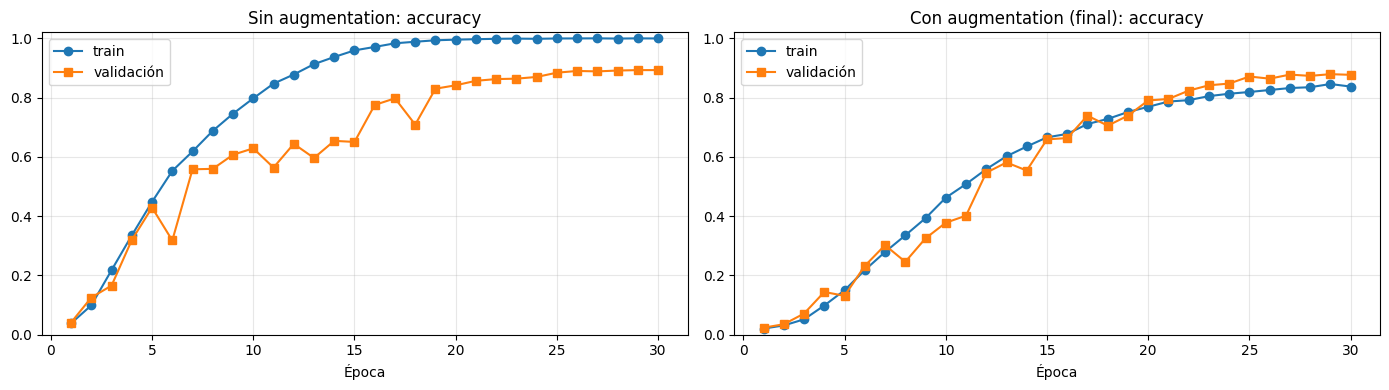

In [18]:
@torch.no_grad()
def embeddings_de(modelo, tabla, lote=256):
    extractor = ExtractorEmbedding(modelo).eval().to(dispositivo)
    cargador = DataLoader(CarasDataset(tabla), batch_size=lote, num_workers=2)
    return np.concatenate([extractor(x.to(dispositivo)).cpu().numpy() for x, _ in cargador])

i_p, j_p, y_p = pares(por_split['test_open'])  # mismos pares de test open-set que en la sección 4
filas_exp = []
for nombre, modelo, hist, aug in [('1. CNN sin augmentation', modelo_exp, historial_exp, 'No'),
                                  ('2. CNN con augmentation (final)', modelo_a, historial, 'Sí')]:
    E = embeddings_de(modelo, por_split['test_open'])
    v = metricas_verificacion((E[i_p] * E[j_p]).sum(1), y_p)
    b = hist.loc[hist['acc_val'].idxmax()]
    filas_exp.append({'Experimento': nombre, 'Augmentation': aug, 'Épocas': len(hist), 'Mejor época': int(b['epoca']),
                      'Acc train': b['acc_train'], 'Acc val': b['acc_val'], 'Brecha train-val': b['acc_train'] - b['acc_val'],
                      'AUC open-set': v['AUC'], 'EER open-set': v['EER'], 'TAR@FAR=1e-3 open-set': v['TAR@FAR=0.001']})
tabla_exp = pd.DataFrame(filas_exp).set_index('Experimento')
modelo_a.train(False)
print(tabla_exp.round(3).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre, hist) in zip(axes, [('Sin augmentation', historial_exp), ('Con augmentation (final)', historial)]):
    ax.plot(hist['epoca'], hist['acc_train'], 'o-', label='train'); ax.plot(hist['epoca'], hist['acc_val'], 's-', label='validación')
    ax.set_title(f'{nombre}: accuracy'); ax.set_xlabel('Época'); ax.set_ylim(0, 1.02); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Resultado:**
| Experimento | Augmentation | Acc train | Acc val | Brecha train-val | AUC open-set | EER open-set | TAR @ FAR = 1e-3 |
|---|---|---|---|---|---|---|---|
| 1. CNN sin augmentation | No | **100%** | **89,3%** | +10,7 pts | 0,807 | 27,0% | 7,2% |
| 2. CNN con augmentation (final) | Sí | 84,6% | 87,9% | -3,3 pts | **0,868** | **21,5%** | **9,4%** |

**Interpretación:**
- **Sin augmentation hay overfitting claro:** la accuracy de train llega al **100%** desde la época 20 (la red memorizó las fotos de entrenamiento) y queda una brecha de casi 11 puntos con validación. Con augmentation, train y validación avanzan juntas.
- **Dato clave:** sin augmentation, la accuracy de **validación es incluso un poco mayor** (89,3% contra 87,9%). Mirando solo la clasificación de las 85 personas conocidas, parecería que la augmentation no ayuda.
- **Pero en el test open-set (personas nuevas), la augmentation mejora claramente:** AUC de 0,807 a 0,868, EER de 27,0% a 21,5% y TAR @ FAR = 1e-3 de 7,2% a 9,4%.
- **Conclusión:** la augmentation no mejora la clasificación de personas conocidas, pero sí la **calidad de los embeddings para personas nuevas**, que es lo que necesita la app. Sin ella, la red aprende detalles específicos de cada foto de entrenamiento (memoriza) en lugar de rasgos generales del rostro. Por eso **se eligió el modelo con augmentation**, aunque su accuracy de validación sea levemente menor.
- Esto muestra que **la accuracy de clasificación closed-set no es una buena métrica para elegir un modelo de reconocimiento facial**: hay que evaluar sobre personas no vistas.

## 5. Comparación y elección final

### 5.1 Tabla comparativa
Todas las métricas se calcularon sobre el mismo test open-set (20 personas que la CNN nunca vio) y con el mismo protocolo para ambos modelos.

In [19]:
filas = {}
for m in MODELOS_CMP:
    filas[m] = {'AUC (verificación)': VER[m]['AUC'], 'EER': VER[m]['EER'], 'TAR @ FAR=1e-2': VER[m]['TAR@FAR=0.01'],
                'TAR @ FAR=1e-3': VER[m]['TAR@FAR=0.001'], 'Top-1 accuracy': IDENT[m]['Top-1 (sin umbral)'],
                'Top-5 accuracy': IDENT[m]['Top-5 (sin umbral)'], 'Precision macro': IDENT[m]['Precision macro'],
                'Recall macro': IDENT[m]['Recall macro'], 'F1 macro': IDENT[m]['F1 macro'],
                'Desconocidos rechazados': IDENT[m]['Desconocidos rechazados'], 'Silhouette (test open)': CLUST[m]['Silhouette'],
                'ARI (test open)': CLUST[m]['ARI (K-Means)'], 'Umbral calibrado (FAR=1e-3, val)': UMBRAL[m]['FAR=1e-3'], **COSTO[m]}
comparacion = pd.DataFrame(filas)
comparacion.round(3)

,CNN propia,ArcFace
AUC (verificación),0.868,1.000
EER,0.215,0.002
TAR @ FAR=1e-2,0.271,0.999
TAR @ FAR=1e-3,0.094,0.996
Top-1 accuracy,0.658,1.000
Top-5 accuracy,0.947,1.000
Precision macro,0.746,0.996
Recall macro,0.414,0.999
F1 macro,0.478,0.998
Desconocidos rechazados,0.873,0.991


### 5.2 Conclusión y elección del modelo

**Modelo elegido para la app: ArcFace (InsightFace `buffalo_l`, `w600k_r50.onnx`)**, con similitud coseno y **umbral 0,243**, calibrado en validación para FAR = 1e-3.

**Justificación:**
| Criterio | CNN propia | ArcFace | Ganador |
|---|---|---|---|
| Verificación (AUC / TAR @ FAR = 1e-3) | 0,868 / 9,4% | ≈ 1,000 / 99,6% | **ArcFace** |
| Identificación (Top-1 / F1 macro) | 65,8% / 0,48 | 100% / 0,998 | **ArcFace** |
| Rechazo de desconocidos | 87,3% | 99,1% | **ArcFace** |
| Costo (inferencia CPU / tamaño) | 17 ms / 4,8 MB | 380 ms / 174 MB | CNN propia |
| Licencia | Propia, sin restricciones | No comercial / investigación | CNN propia |
| Integración | ONNX, 128 dimensiones | ONNX, 512 dimensiones, ya soportado por la app | Empate |

- **Desempeño:** es el criterio decisivo. En una app de reconocimiento, confundir a una persona con otra o no reconocer a alguien registrado son errores graves. Con la CNN propia, para que casi no confunda personas hay que rechazar a la mayoría de las personas registradas, lo que la hace inutilizable en la práctica.
- **Costo:** la CNN es unas 22 veces más rápida, pero 0,4 s por rostro es aceptable para una app que procesa una foto por pedido.
- **Licencia:** la restricción no comercial de InsightFace es compatible con un trabajo académico. En un producto comercial habría que licenciar el modelo o entrenar uno propio.

**¿Por qué la CNN propia rinde menos?**
1. **Datos:** se entrenó con unas 11.000 imágenes de 85 personas. ArcFace se entrenó con WebFace600K: unas **600.000 identidades**. Para aprender qué distingue a cualquier cara de cualquier otra hacen falta muchísimas personas distintas, no solo muchas fotos de pocas personas.
2. **Función de pérdida:** la CNN usa softmax / cross-entropy, que solo exige separar las 85 clases de entrenamiento, **sin margen** entre ellas. ArcFace usa una pérdida de **margen angular** que obliga explícitamente a que las caras de una persona queden juntas y lejos de las demás. Por eso sus embeddings generalizan a personas nuevas, y los de la CNN quedan superpuestos (histogramas de 4.2).
3. **Capacidad:** 1,2 millones de parámetros frente a 43,6 millones (ResNet-50). La red chica aprende rasgos más superficiales (peinado, color, accesorios), como muestran los falsos negativos: caracterizaciones, anteojos y cambios de edad la desorientan.
4. **Objetivo de entrenamiento distinto del de evaluación:** la CNN alcanzó 87,9% de accuracy en validación (personas conocidas), pero en personas nuevas su desempeño cae (Top-1 de 65,8% entre solo 15 personas). Clasificar bien a las personas del entrenamiento no garantiza buenos embeddings para personas nuevas.

**Lo que sí logró la CNN:** generaliza parcialmente a personas que nunca vio (AUC de 0,87, Top-5 de 94,7% y ARI de 0,50, muy por encima del azar), sin overfitting, y siendo 36 veces más chica.

**Posibles mejoras:** entrenar con una pérdida de margen (ArcFace / CosFace o triplet loss), usar un dataset con muchas más identidades (por ejemplo CASIA-WebFace, con unas 10.000), hacer *fine-tuning* de un backbone preentrenado (ResNet-18 / MobileNet) en lugar de entrenar desde cero, o entrenar más épocas, ya que la validación seguía mejorando levemente al final.